# A Basic Introduction to JAX

This notebook introduces basic use of **JAX** along with **Flax** and **Optax**.

It includes an introduction to just-in-time compilation and a simple example of how `jax.grad` can be used to calculate gradients.

This is followed by code which constructs a simple neural network, runs a single forward pass, and then runs a full training loop.As you go through this notebook, I recommend that you compare the code with the PyTorch examples that you saw earlier. You'll see that for many standard things that you would like to do with neural networks, JAX (when used with Flax and Optax) can look very similar to PyTorch (or, as you'll see later, TensorFlow). The advantages of JAX mostly come when you are trying to optimise, scale, and parallelise neural network operations over multiple processors or GPUs -- particularly if you're doing this in novel or unusual ways. The details of this are beyond the scope of this course.

We start as usual by importing the necessary libraries, including matplotlib, which we'll use later for plotting:

In [1]:
import jax
import jax.numpy as jnp
import flax
import flax.nnx as nnx
import optax
import matplotlib.pyplot as plt

## Introducing `jax.jit`

In this section we're going to do some basic performance measurements to show the effect of just-in-time compilation in JAX.

We'll use the `%timeit` functionality available in Jupyter notebooks.

A few points:

- Normally you'd do performance calculations over multiple runs and look at average/minimum/maximum times, depending on what you're interested in, but in this case we're going to deliberately run the function only once. The reason, as you'll see, is that we want to observe the difference between the first run of the function and subsequent runs of the function. To do this, we'll use `-n 1 -r 1` with `%timeit` so that it only makes one function call.
- We have to use `block_until_ready()` because JAX functions are asynchronous: they can return before they complete calculating their return value.
- This notebook is not running in a completely isolated environment, so it's possible that load on the machine could make the results less reliable. If you see unusual results, you may want to repeat the whole process -- from the point where you clear caches -- a number of times to see if the unusual run was an outlier that can be ignored.

To make sure we have a "clean" environment with no previously cached compiled functions, we'll start by clearing any previously cached/compiled functions.

In [2]:
jax.clear_caches()

We'll use a function that has a number of mathematical operations that can have the potential to be chained and combined, and we'll operate on a sufficiently large vector to ensure that the function takes long enough to give us reasonably reliable performance measurements.

In [3]:
def my_function(x):
    for i in range(100):
        x = jnp.sin(x) + jnp.cos(x) * 0.5
        x = x * 1.01 + 0.1
    return x

In [4]:
x = jnp.ones((1000000,))

In [5]:
%timeit -n 1 -r 1 my_function(x).block_until_ready()

723 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


You'll probably observe that this function takes roughly 400-600ms to complete.

Now let's compiled the function:

In [6]:
compiled_function = jax.jit(my_function)

And we'll run the compiled function:

In [7]:
%timeit -n 1 -r 1 compiled_function(x).block_until_ready()

3.17 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


You will probably see that this takes about 3 seconds to complete, which is much slower than the uncompiled version! Let's run it again:

In [8]:
%timeit -n 1 -r 1 compiled_function(x).block_until_ready()

35.4 ms ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


You should see that it now runs in about 30-45ms, a significant speed up on the original function.

This is because the _actual_ compilation of the function happens on the first call: just-in-time.

In fact, it is often necessary for the system to recompile the function if you change the dimension of the inputs. You could experiment with this to see if you can observe this effect.

## A Simple Example of Automatic Differentiation
Let's start with some simple code that demonstrates the use of `jax.grad` to compute gradients.

We're going to calculate the derivative (gradient) of the function:
$$
y=(3x+4)^2
$$
by splitting it into 3 operations:
$$
a=3\times x
$$
$$
b=a+4
$$
$$
y=b^2
$$
`jax.grad` uses the chain rule of differentiation...
$$
\frac{dy}{dx}=\frac{\partial y}{\partial b}\frac{\partial b}{\partial a}\frac{\partial a}{\partial x}
$$
... along with knowledge of how to differentiate operations like addition, multiplication and raising to a power, to calculate the gradient of the `compute` function:


In [9]:
# Create a scalar array.
# No requires_grad=True equivalent is needed.
x = jnp.array(2.0)
print("x:", x)

# Define the computation as a function.
def compute(x):
    a = x * 3
    b = a + 4
    y = b ** 2
    return y

# Evaluate the function (eager execution).

y = compute(x)

print("\nResult:", y)

# Automatic differentiation.

dy_dx = jax.grad(compute)(x)

print("\nAutograd result:")

print("x.grad =", dy_dx)

print("Expected gradient =", 2 * (3 * x + 4) * 3)

x: 2.0

Result: 100.0

Autograd result:
x.grad = 60.0
Expected gradient = 60.0


## A Basic Neural Network

We'll now look at the code to construct the neural network architecture. Notice how `nnx` from the Flax library is used to define the layers of the network and their connectivity. You should see that this is very similar to the way this is done in PyTorch with `torch.nn`. Notice that we don't have to define the width of our neural network (the number of nodes per layer) at this stage.

In [10]:
class DeepFeedForwardNN(nnx.Module):

    def __init__(self, input_dim, hidden_dim1, hidden_dim2, output_dim, rngs):

        # Fully connected layer from input to first hidden layer
        self.fc1 = nnx.Linear(input_dim, hidden_dim1, rngs=rngs)

        # Use ReLU non-linear activation function after first hidden layer  
        self.relu1 = nnx.relu
        
        # Fully connected layer from first hidden layer to second
        self.fc2 = nnx.Linear(hidden_dim1, hidden_dim2, rngs=rngs)

        # Use ReLU non-linear activation function after second hidden layer
        self.relu2 = nnx.relu
        
        # Fully connected layer from second hidden layer to output
        self.fc3 = nnx.Linear(hidden_dim2, output_dim, rngs=rngs)

    def __call__(self, x):
        x = self.fc1(x)
        x = self.relu1(x)
        x = self.fc2(x)
        x = self.relu2(x)
        x = self.fc3(x)
        return x

We'll now create a neural network with the architecture defined above (with the the width of the layers now specified) and look at a couple of ways to inspect it to see the parameters:

In [11]:
# Use a separate demonstration model so this inspection does not
# alter the model that will be trained in main().

demo_model = DeepFeedForwardNN(
    input_dim=2,
    hidden_dim1=10,
    hidden_dim2=10,
    output_dim=1,
    rngs=nnx.Rngs(0)
)

# Inspect model parameters.
print("Model parameters:")

for path, node in nnx.iter_graph(demo_model):
    if isinstance(node, nnx.Variable):
        print(f"{path}: shape={node[...].shape}")

Model parameters:
('fc1', 'bias'): shape=(10,)
('fc1', 'kernel'): shape=(2, 10)
('fc2', 'bias'): shape=(10,)
('fc2', 'kernel'): shape=(10, 10)
('fc3', 'bias'): shape=(1,)
('fc3', 'kernel'): shape=(10, 1)


In [12]:
print("Model parameters:")
for path, value in nnx.state(demo_model).flat_state():
    print(f"{path}: shape={value[...].shape}")

Model parameters:
('fc1', 'bias'): shape=(10,)
('fc1', 'kernel'): shape=(2, 10)
('fc2', 'bias'): shape=(10,)
('fc2', 'kernel'): shape=(10, 10)
('fc3', 'bias'): shape=(1,)
('fc3', 'kernel'): shape=(10, 1)


In [13]:
# A normal input array is sufficient:
demo_input = jnp.array([[1.0, 2.0]])
demo_target = jnp.array([[3.0]])

# Forward pass:
demo_prediction = demo_model(demo_input)

# Calculate loss:
def loss_fn(model):
    prediction = model(demo_input)
    return jnp.mean((prediction - demo_target) ** 2)
demo_loss = loss_fn(demo_model)

print("\nForward pass:")
print("Input:", demo_input)
print("Prediction:", demo_prediction)
print("Loss:", demo_loss)


Forward pass:
Input: [[1. 2.]]
Prediction: [[0.26871717]]
Loss: 7.459905


**Note:** At this point, unlike in the PyTorch example, there is no computational graph that has been constructed and stored within model.

In [14]:
print("\nGraph-related information:")
print("Input type:", type(demo_input))
print("Prediction type:", type(demo_prediction))
print("Loss type:", type(demo_loss))


Graph-related information:
Input type: <class 'jaxlib._jax.ArrayImpl'>
Prediction type: <class 'jaxlib._jax.ArrayImpl'>
Loss type: <class 'jaxlib._jax.ArrayImpl'>


We can see that all of these things are all ordinary JAX arrays (containing the values shown above) with no additional information about gradients or a computational graph.

We have to explicitly calculate the gradients, but as you can see below, we can pass in the whole model at once to calculate the gradients with a single call.

In [15]:
grads = nnx.grad(loss_fn)(demo_model)
grads

State({
  'fc1': {
    'bias': Param( # 10 (40 B)
      value=Array([ 0.        ,  0.        ,  0.        ,  0.        ,  1.7631056 ,
              0.10936347, -0.6744745 ,  0.        , -1.4846029 ,  0.        ],      dtype=float32)
    ),
    'kernel': Param( # 20 (80 B)
      value=Array([[ 0.        ,  0.        ,  0.        ,  0.        ,  1.7631056 ,
               0.10936347, -0.6744745 ,  0.        , -1.4846029 ,  0.        ],
             [ 0.        ,  0.        ,  0.        ,  0.        ,  3.5262113 ,
               0.21872693, -1.348949  ,  0.        , -2.9692059 ,  0.        ]],      dtype=float32)
    )
  },
  'fc2': {
    'bias': Param( # 10 (40 B)
      value=Array([ 0.        ,  0.        ,  2.3461459 ,  0.22759734,  0.        ,
              1.2902063 , -1.483204  , -2.966479  , -0.78649855,  0.5007078 ],      dtype=float32)
    ),
    'kernel': Param( # 100 (400 B)
      value=Array([[ 0.        ,  0.        ,  0.        ,  0.        ,  0.        ,
               0.  

## Training the Model

We now move on from a single forward pass to some code for training the model.

The train_model() function trains the neural network over 1,000 epochs. In each epoch, the model generates predictions, calculates the loss, computes gradients through backpropagation, and updates the model parameters using the optimiser. Training progress is displayed every 100 epochs to monitor the reduction in loss. Then Epochs vs Loss is plotted.

In [16]:
def train_model(sample_data, labels, model, optimizer):
    """
    Training loop for the neural network
    """
    num_epochs = 1000
    epoch_losses = []
    
    # Define loss function.
    def loss_fn(model):
        predictions = model(sample_data)
        loss = jnp.mean((predictions - labels) ** 2)
        return loss
    
    for epoch in range(num_epochs):
        
        # Calculate loss and gradients.
        loss, grads = nnx.value_and_grad(loss_fn)(model)
        
        # Update model parameters using the optimiser.
        optimizer.update(model, grads)
        
        # Store loss for plotting.
        epoch_losses.append(float(loss))
        
        # Print progress.
        if (epoch + 1) % 100 == 0:
            print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {float(loss):.6f}')
    
    # Plot Epoch vs Loss.
    plt.figure(figsize=(8, 5))
    plt.plot(range(1, num_epochs + 1), epoch_losses, label='Training loss')
    plt.xlabel('Epoch')
    plt.ylabel('Loss')
    plt.title('Epoch vs Loss')
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    plt.show()
    
    return epoch_losses

In [17]:
def main():
    """
    Sets up NN configuration and training data, then trains the model
    and tests it with new data.
    """
    # Sample data for training the neural network
    input_dim = 2
    hidden_dim1 = 10
    hidden_dim2 = 10
    output_dim = 1
    sample_data = jnp.array([
        [1.0, 2.0],
        [2.0, 3.0],
        [3.0, 4.0],
        [4.0, 5.0],
        [5.0, 6.0]
    ])
    print(f"Shape of sample_data = {sample_data.shape}")
    print(f"sample_data = \n {sample_data}")

    # Define the ground truth labels (the sum of two input values)
    labels = jnp.sum(sample_data, axis=1, keepdims=True)
    print(f"Shape of labels = {labels.shape}")
    print(f"labels = \n {labels}")

    # Create an instance of the deep neural network
    model = DeepFeedForwardNN(
        input_dim,
        hidden_dim1,
        hidden_dim2,
        output_dim,
        rngs=nnx.Rngs(0)
    )

    # Define the optimizer
    optimizer = nnx.Optimizer(
        model,
        optax.sgd(learning_rate=0.0001),
        wrt=nnx.Param
    )

    # Train the model
    train_model(sample_data, labels, model, optimizer)

    print("\nModel training complete.")
    
    # Test the model with new unseen data
    test_data = jnp.array([
        [6.0, 7.0],
        [7.0, 8.0],
        [8.0, 9.0]
    ])

    # Forward pass 
    test_predictions = model(test_data)

    print("\nTest data:")
    print(test_data)
    print("\nPredictions for test data:")
    print(test_predictions)

The code below can be used to measure the runtime of a single run of the main function:

Shape of sample_data = (5, 2)
sample_data = 
 [[1. 2.]
 [2. 3.]
 [3. 4.]
 [4. 5.]
 [5. 6.]]
Shape of labels = (5, 1)
labels = 
 [[ 3.]
 [ 5.]
 [ 7.]
 [ 9.]
 [11.]]
Epoch [100/1000], Loss: 0.014919
Epoch [200/1000], Loss: 0.008804
Epoch [300/1000], Loss: 0.008568
Epoch [400/1000], Loss: 0.008339
Epoch [500/1000], Loss: 0.008116
Epoch [600/1000], Loss: 0.007900
Epoch [700/1000], Loss: 0.007689
Epoch [800/1000], Loss: 0.007485
Epoch [900/1000], Loss: 0.007286
Epoch [1000/1000], Loss: 0.007093


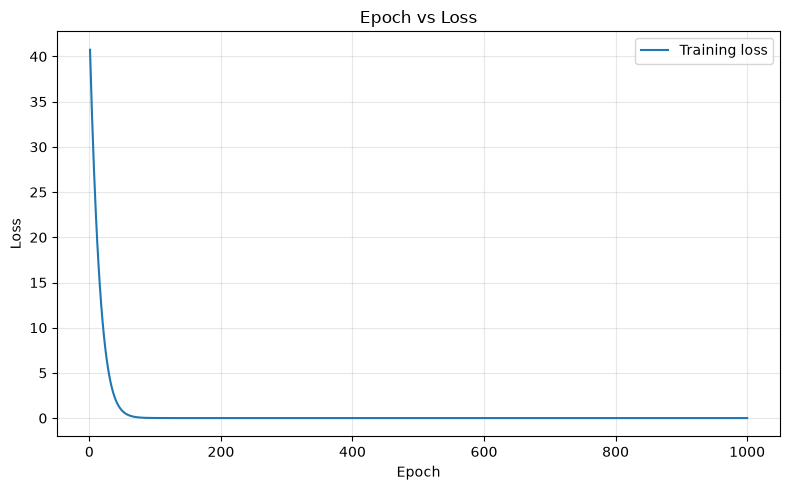


Model training complete.

Test data:
[[6. 7.]
 [7. 8.]
 [8. 9.]]

Predictions for test data:
[[13.140521]
 [15.198769]
 [17.257017]]
23.7 s ± 0 ns per loop (mean ± std. dev. of 1 run, 1 loop each)


In [18]:
%timeit -r 1 -n 1 main()

# Things to try

- Try changing the learning rate
- Try changing the optimiser: swap `optax.adam` for `optax.sgd`
- Try changing the activation function: swap `nnx.sigmoid` for `nnx.relu`
- Try compiling one of the functions in the loop over epochs
    - Can you get the code to speed up?
    - If you only run 1 epoch, is the speed up worth it?

**Hints:**
- If you try to use `jax.jit` to compile an nnx function, you will probably find that it doesn't work! This is because nnx is more object oriented and has more complicated contstructs that `jax.jit` doesn't know how to compile. The good news is that you can simply replace `jax.jit` with `nnx.jit` and the code will probably work and this method is "nnx-aware" and can work with most nnx functions/methods.
- If you try to compile nnx.value_and_grad you'll find that it doesn't work. The required approach is to _first_ get a function from `nnx.value_and_grad(loss_fn)` and then to compile this function.

## Acknowledgements and Re-use
&copy; 2026 The University of Edinburgh.

This notebook was created by Adam Carter, EPCC, The University of Edinburgh as part of the UKAIFA project. Parts of the notebook are based on a PyTorch example written by Charaka Palansuriya, EPCC. You're welcome to reuse this notebook and its contents under the terms of CC-BY-4.0.